In [3]:
import pandas as pd
import numpy as np

In [4]:
df=pd.read_csv("powerplant_data.csv")

In [5]:
df.head()

,AT,V,AP,RH,PE
0,8.34,40.77,1010.84,90.01,480.48
1,23.64,58.49,1011.40,74.20,445.75
2,29.74,56.90,1007.15,41.91,438.76
3,19.07,49.69,1007.22,76.79,453.09
4,11.80,40.66,1017.13,97.20,464.43


In [6]:
# AT => temperature
# V => vaccum
# AP => pressure
# RH=> humidity

#PE => produced energy

In [7]:
df.isnull().sum()

AT    0
V     0
AP    0
RH    0
PE    0
dtype: int64

In [8]:
X=df.drop("PE",axis=1)
y=df["PE"]

In [9]:
y.head()

0    480.48
1    445.75
2    438.76
3    453.09
4    464.43
Name: PE, dtype: float64

In [10]:
#split data
from sklearn.model_selection import train_test_split

X_train,X_test,y_train,y_test=train_test_split(
    X,y,test_size=0.2,random_state=42
)

In [11]:
df.shape

(9568, 5)

In [12]:
from sklearn.preprocessing import StandardScaler

scaler=StandardScaler()

X_train_scaled=scaler.fit_transform(X_train)
X_test_scaled=scaler.transform(X_test)

In [13]:
X_test_scaled

array([[ 1.34499288,  0.23869298, -1.28658067, -1.10532538],
       [ 0.81095912,  1.36269098, -0.74140656,  0.26485915],
       [-0.2437241 , -0.73900436,  1.99970178, -0.19713193],
       ...,
       [-0.67068342, -1.15902881, -0.29951077, -0.10651852],
       [ 1.31420898,  1.33752097, -0.87346737, -0.44288647],
       [-0.2611237 , -0.27021304,  0.37433797,  1.10646548]],
      shape=(1914, 4))

In [14]:
import torch
import torch.nn as nn

X_train_tensor=torch.tensor(X_train_scaled,dtype=torch.float32)
y_train_tensor=torch.tensor(y_train.values,dtype=torch.float32).view(-1,1)


X_test_tensor=torch.tensor(X_test_scaled,dtype=torch.float32)
y_test_tensor=torch.tensor(y_test.values,dtype=torch.float32).view(-1,1)

In [15]:
type(X_train_scaled)

numpy.ndarray

In [16]:
type(y_train)

pandas.core.series.Series

In [17]:
from torch.utils.data import TensorDataset, DataLoader

train_dataset=TensorDataset(X_train_tensor,y_train_tensor)
test_dataset=TensorDataset(X_test_tensor,y_test_tensor)

In [18]:
train_loader=DataLoader(train_dataset,batch_size=32,shuffle=True)
test_loader=DataLoader(test_dataset,batch_size=32)

### deep learning

In [44]:
# defined our ANN model

class ANN(nn.Module):
    def __init__(self):
        super(ANN,self).__init__()

        self.model=nn.Sequential(
            #1st hidden layer
            nn.Linear(X_train.shape[1],6),
            nn.ReLU(),

            #second hidden layer
            nn.Linear(6,6),
            nn.ReLU(),

            #output layer
            nn.Linear(6,1)
        )

    def forward(self,x):
        return self.model(x)

In [45]:
import torch.optim as optim

model=ANN()

#loss,optimizer
criterion=nn.MSELoss()
optimizer=optim.Adam(model.parameters())

# train the ANN



In [46]:

train_losses=[]
val_losses=[]

best_val_loss=float("inf")

epochs=100

for epoch in range(epochs):
    model.train()
    running_loss=0.0 #total training loss for 1 epoch
    
    for xb,yb, in train_loader:
        # xb=features of one batch
        # yb=labels of one batch
        optimizer.zero_grad()
        
        outputs=model(xb) #forward propagation.......... predicted outputs for this batch
        loss=criterion(outputs, yb) #compute loss
        loss.backward() #backward propagation....compute gradiants
        optimizer.step() #updatae params
        
        running_loss+=loss.item() #loss is a tensor value to which we convert it into float value
        #running_loss=>loss for all batches
        #loss=>loss for 1 batch

    epoch_train_loss=running_loss / len(train_loader)
    train_losses.append(epoch_train_loss)


    #validation
    model.eval()
    running_val_loss=0.0

    with torch.no_grad(): #no gradients compute
        for xb,yb in test_loader:
            outputs=model(xb)
            loss=criterion(outputs, yb) #compute loss
            running_val_loss+=loss

    epoch_val_loss=running_val_loss / len(test_loader)
    val_losses.append(epoch_val_loss)

    print(f"epoch {epoch+1}/{epochs} ==> training loss = {epoch_train_loss} & val_loss={epoch_val_loss}")

    if epoch_val_loss<best_val_loss:
        best_val_loss=epoch_val_loss
        torch.save(model.state_dict(),"best_model.pt")#.pt or .pth

epoch 1/100 ==> training loss = 205903.28040364583 & val_loss=203973.9375
epoch 2/100 ==> training loss = 197825.67024739584 & val_loss=187821.8125
epoch 3/100 ==> training loss = 168437.89947916666 & val_loss=145063.25
epoch 4/100 ==> training loss = 116318.32145182292 & val_loss=88760.46875
epoch 5/100 ==> training loss = 65324.872330729166 & val_loss=47644.765625
epoch 6/100 ==> training loss = 36689.07513020833 & val_loss=29468.853515625
epoch 7/100 ==> training loss = 25204.333581542967 & val_loss=22153.48828125
epoch 8/100 ==> training loss = 19976.076098632813 & val_loss=18068.11328125
epoch 9/100 ==> training loss = 16529.978963216145 & val_loss=14807.970703125
epoch 10/100 ==> training loss = 13388.183459472657 & val_loss=11667.46484375
epoch 11/100 ==> training loss = 10286.513390096028 & val_loss=8697.5224609375
epoch 12/100 ==> training loss = 7471.786558024089 & val_loss=6077.2412109375
epoch 13/100 ==> training loss = 5034.834675089518 & val_loss=3952.71826171875
epoch 14

In [47]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


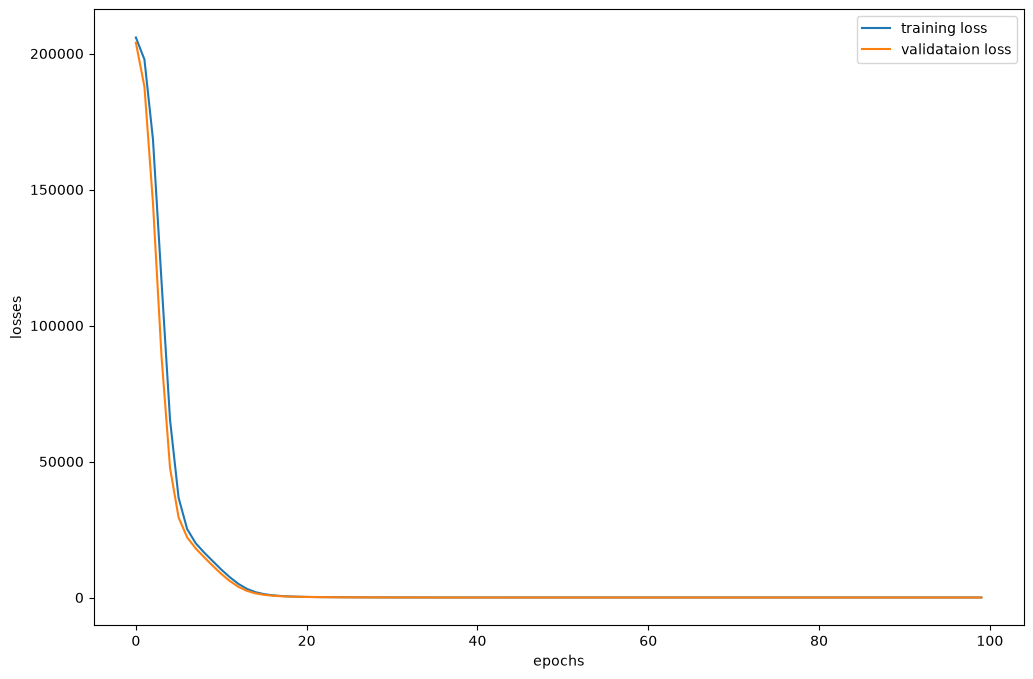

In [48]:
import matplotlib.pyplot as plt

loss_df=pd.DataFrame({
    "training loss":train_losses,
    "validataion loss":val_losses
})

plt.figure(figsize=(12,8))
plt.plot(loss_df["training loss"],label="training loss")
plt.plot(loss_df["validataion loss"],label="validataion loss")

plt.xlabel("epochs")
plt.ylabel("losses")
plt.legend()

In [50]:
#loading the best model
model.load_state_dict(torch.load("best_model.pt"))

<All keys matched successfully>

In [53]:
#evaluate our model:

model.eval()
with torch.no_grad():
    train_pred=model(X_train_tensor)
    test_pred=model(X_test_tensor)
    
    train_mse_loss=criterion(train_pred,y_train_tensor)
    test_mse_loss=criterion(test_pred,y_test_tensor)


print("training mse:",train_mse_loss.item())
print("testing mse:",test_mse_loss.item())

training mse: 21.32358169555664
testing mse: 19.55600929260254


In [54]:
from sklearn.metrics import r2_score

print("r^2 score:",r2_score(y_test,test_pred))

r^2 score: 0.9316567928231774


In [59]:
import numpy as np
predicted_df=pd.DataFrame(test_pred.numpy(),columns=["predicted values"])
actual_df=pd.DataFrame(y_test.values,columns=["actual values"])


pd.concat([predicted_df,actual_df],axis=1)

,predicted values,actual values
0,435.007965,433.27
1,437.003937,438.16
2,461.399384,458.42
3,476.338837,480.82
4,435.615326,441.41
...,...,...
1909,451.033844,456.70
1910,431.580353,438.04
1911,467.217987,467.80
1912,431.130798,437.14
